<a href="https://colab.research.google.com/github/telloudi-khadijaencg-alt/23009059-TELLOUDIKHADIJA-G3FINANCE/blob/main/notebooks/projet_F21.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# F21 : Force du dollar

**Nom et prénom :** Telloudi Khadija    **Code Apogée :** 23009059    **Groupe :** G3FINANCE    **Filière :** S7 FIN    **Date :** 17/11/2026

**Dépôt GitHub :** https://github.com/telloudi-khadijaencg-alt/23009059-TELLOUDIKHADIJA-G3FINANCE

## 1. Sujet et problématique
- **Intérêt du sujet :** Le dollar influence les coûts d'importation, les exportations et la valeur des actifs internationaux, donc les entreprises exportatrices, les investisseurs et les banques centrales suivent son évolution. Un modèle qui anticipe son rendement du mois suivant pourrait aider à décider de la couverture du risque de change.
- **Problématique :** Les rendements passés du dollar permettent-ils de prévoir son rendement du mois suivant mieux qu'une règle naïve ?
- **Objectif mesurable :** RMSE sur le test inférieur d'au moins 2 % à celui de la moyenne d'apprentissage, test de 2020 à la dernière donnée.
- **Nature du problème :** régression sur série temporelle.
- **Algorithme principal envisagé :** n°2 (Ridge)

In [5]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import sklearn, sys
GRAINE = 42
np.random.seed(GRAINE)
print(sys.version, sklearn.__version__, pd.__version__)

3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0] 1.6.1 2.2.3


## 2. Jeu de données

- **Source :** FRED (Federal Reserve Bank of St. Louis), série DTWEXBGS, indice nominal large du dollar américain.
- **URL :** https://fred.stlouisfed.org/series/DTWEXBGS
- **Date d'extraction :** 17/11/2026
- **Licence :** (écris ce que dit la page FRED de la série ; si rien n'est indiqué, écris « non précisée »)
- **Taille et période :** ... observations, du ... au ..., fréquence quotidienne (jours ouvrés)
- **Unité d'observation :** un jour ouvré, puis un mois après agrégation en fin de mois
- **Variable cible :** rendement mensuel du mois suivant, en % (`cible`)
- **Adéquation :** la série couvre le dollar contre un panier large de monnaies pondéré par le commerce, ce qui permet d'étudier sa force globale.
- **Limites :** période courte (depuis 2006), une seule grande phase de dollar fort, chocs de 2008 et 2020 qui peuvent changer le régime, jours fériés manquants, série éventuellement révisée.

In [6]:
URL = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=DTWEXBGS"
Path("data/raw").mkdir(parents=True, exist_ok=True)
raw = pd.read_csv(URL, index_col=0, parse_dates=True)
raw.to_csv("data/raw/DTWEXBGS.csv")
raw = pd.read_csv("data/raw/DTWEXBGS.csv", index_col=0, parse_dates=True)
raw.columns = ["indice"]
raw["indice"] = pd.to_numeric(raw["indice"], errors="coerce")

print(raw.shape, raw.index.min(), raw.index.max())
print(raw.isna().sum())
print(raw.describe())
print(raw.head())

(5445, 1) 2006-01-02 00:00:00 2026-11-13 00:00:00
indice    214
dtype: int64
            indice
count  5231.000000
mean    106.558713
std      12.366974
min      85.469200
25%      93.803650
50%     110.303400
75%     117.299750
max     130.041300
                    indice
observation_date          
2006-01-02        101.4155
2006-01-03        100.7558
2006-01-04        100.2288
2006-01-05        100.2992
2006-01-06        100.0241


| Variable | Description | Type | Unité | Rôle | Manquants (%) |
|---|---|---|---|---|---|
| indice | Niveau de l'indice large du dollar | numérique | points d'indice | brute | ... |
| r | Rendement mensuel = 100 × variation du log de l'indice fin de mois | numérique | % | explicative (retardée) | ... |
| r_lag1, r_lag2, r_lag3 | Rendements des 1, 2 et 3 mois précédents | numérique | % | explicative | ... |
| vol3 | Écart-type des rendements sur 3 mois, jusqu'à t | numérique | % | explicative | ... |
| mom12 | Somme des rendements sur 12 mois, jusqu'à t | numérique | % | explicative | ... |
| cible | Rendement du mois suivant (r décalé de −1) | numérique | % | cible | ... |

**Interprétation.** Le jeu contient 5 445 observations quotidiennes (jours ouvrés), du 2 janvier 2006 au 13 novembre 2026, soit environ 21 ans de données. La série comporte 214 valeurs manquantes (3,9 %), qui correspondent aux jours fériés où le marché est fermé et que FRED laisse vides. Je ne les supprime pas à ce stade : en prenant la dernière valeur de chaque mois, ces trous disparaissent, car chaque mois contient au moins un jour de cotation. L'indice varie entre 85,5 et 130,0 points, avec une moyenne de 106,6 et un écart-type de 12,4, ce qui montre que le dollar a connu de longues phases de hausse et de baisse sur la période. La période étant courte (environ 250 rendements mensuels), il faut rester prudent sur la complexité du modèle et sur la portée des conclusions.

In [7]:
m = raw["indice"].resample("ME").last().dropna()   # dernière valeur de chaque mois
m = m[m.index < "2026-11-01"]                       # on retire novembre 2026 (incomplet)

df = pd.DataFrame({"r": np.log(m).diff() * 100})    # rendement mensuel en %
for k in (1, 2, 3):
    df[f"r_lag{k}"] = df["r"].shift(k)              # rendements des mois précédents
df["vol3"] = df["r"].rolling(3).std()               # volatilité sur 3 mois, jusqu'à t
df["mom12"] = df["r"].rolling(12).sum()             # somme des rendements sur 12 mois
df["cible"] = df["r"].shift(-1)                     # rendement du mois SUIVANT
df = df.dropna()

print(df.shape)
print(df.head())
print(df.tail())

(237, 7)
                         r    r_lag1    r_lag2    r_lag3      vol3     mom12  \
observation_date                                                               
2007-01-31        0.956749  0.468264 -0.837463 -0.731785  0.927607 -1.486488   
2007-02-28       -0.743231  0.956749  0.468264 -0.837463  0.875240 -2.569477   
2007-03-31       -0.950942 -0.743231  0.956749  0.468264  1.046610 -4.309623   
2007-04-30       -1.550398 -0.950942 -0.743231  0.956749  0.419128 -3.425290   
2007-05-31       -0.544520 -1.550398 -0.950942 -0.743231  0.506017 -3.591374   

                     cible  
observation_date            
2007-01-31       -0.743231  
2007-02-28       -0.950942  
2007-03-31       -1.550398  
2007-04-30       -0.544520  
2007-05-31       -0.193356  
                         r    r_lag1    r_lag2    r_lag3      vol3     mom12  \
observation_date                                                               
2026-05-31        0.174532 -1.972480  2.690220 -0.065586  2.333778 

In [8]:
from google.colab import files
files.download("data/raw/DTWEXBGS.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

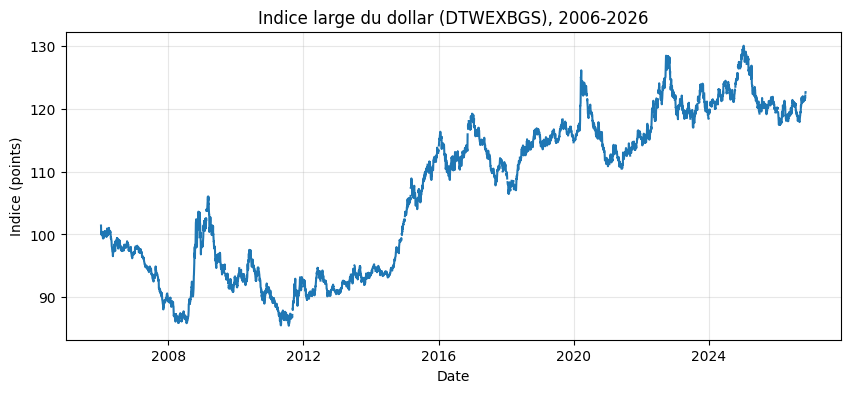

In [9]:
Path("figures").mkdir(exist_ok=True)
plt.figure(figsize=(10, 4))
plt.plot(raw.index, raw["indice"])
plt.title("Indice large du dollar (DTWEXBGS), 2006-2026")
plt.xlabel("Date")
plt.ylabel("Indice (points)")
plt.grid(alpha=0.3)
plt.savefig("figures/graph1_indice.png", dpi=150, bbox_inches="tight")
plt.show()


**Interprétation.** L'indice large du dollar évolue entre 85 et 130 points sur 2006-2026. On distingue de longues phases : une baisse de 2006 à 2008 (vers 86 points), une pointe brutale fin 2008-début 2009 liée à la crise financière, un point bas vers 2011, puis une forte hausse de 2014 à 2016 (jusqu'à environ 115). Le niveau monte ensuite par paliers, avec une nouvelle pointe en 2020 (choc du Covid) et un sommet proche de 130 points en 2022-2025. La série n'oscille pas autour d'une valeur fixe : son niveau dérive dans le temps, donc elle n'est pas stationnaire. Je ne modélise donc pas le niveau, mais les rendements mensuels, qui sont plus stables et comparables d'une période à l'autre.

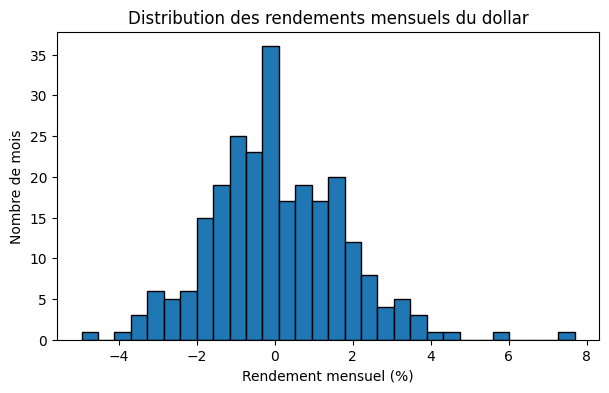

count    249.000000
mean       0.081049
std        1.725122
min       -4.951767
25%       -1.015185
50%       -0.106071
75%        1.226214
max        7.694817
Name: indice, dtype: float64
observation_date
2008-10-31    7.694817
2011-09-30    5.848052
2009-05-31    4.951767
Name: indice, dtype: float64


In [10]:
m_exp = raw["indice"].resample("ME").last()
m_exp = m_exp[m_exp.index < "2026-11-01"]
r_exp = np.log(m_exp).diff() * 100

plt.figure(figsize=(7, 4))
plt.hist(r_exp.dropna(), bins=30, edgecolor="black")
plt.title("Distribution des rendements mensuels du dollar")
plt.xlabel("Rendement mensuel (%)")
plt.ylabel("Nombre de mois")
plt.savefig("figures/graph2_rendements.png", dpi=150, bbox_inches="tight")
plt.show()

print(r_exp.describe())
print(r_exp.abs().sort_values(ascending=False).head(3))

**Interprétation.** Les 249 rendements mensuels forment une distribution à peu près symétrique et centrée autour de 0 %, la plupart des mois se situant entre -2 % et +2 %. Cela montre que le dollar varie peu d'un mois à l'autre et qu'il n'y a pas de tendance mensuelle nette. Quelques mois extrêmes se détachent, de l'ordre de -5 % à +8 %, donc la distribution a des queues un peu plus lourdes qu'une loi normale. Ces valeurs correspondent à de vrais épisodes de tension sur les marchés, donc je les conserve : les supprimer ferait disparaître justement les situations que le modèle doit apprendre à gérer. Il faudra en revanche les garder à l'esprit en analysant les erreurs, car la RMSE y est sensible.

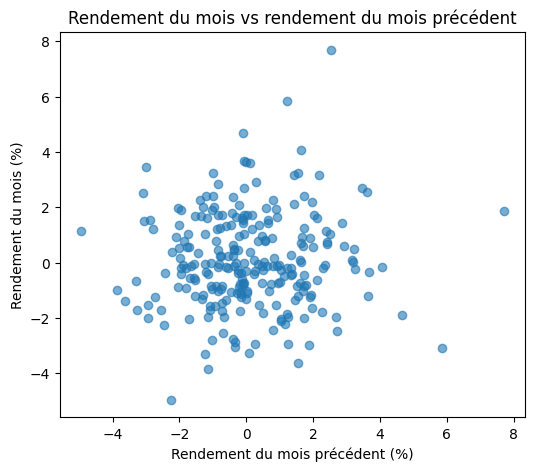

Corrélation : 0.04381638210197474


In [11]:
d = pd.concat([r_exp.shift(1), r_exp], axis=1).dropna()
d.columns = ["r_prec", "r"]

plt.figure(figsize=(6, 5))
plt.scatter(d["r_prec"], d["r"], alpha=0.6)
plt.title("Rendement du mois vs rendement du mois précédent")
plt.xlabel("Rendement du mois précédent (%)")
plt.ylabel("Rendement du mois (%)")
plt.savefig("figures/graph3_nuage.png", dpi=150, bbox_inches="tight")
plt.show()

print("Corrélation :", d["r_prec"].corr(d["r"]))

**Interprétation.** Les points forment un nuage sans forme, sans pente visible, et la corrélation entre le rendement d'un mois et celui du mois précédent est de 0,044, c'est-à-dire pratiquement nulle. Le rendement du mois passé n'apporte donc quasiment aucune information sur celui du mois suivant, ce qui est cohérent avec l'idée que le taux de change se rapproche d'une marche aléatoire. Je m'attends donc à ce que le modèle ait du mal à battre la référence naïve, et un résultat proche de la référence, voire légèrement moins bon, serait un résultat honnête et interprétable. Quelques points isolés (rendements supérieurs à 5 % en valeur absolue) correspondent aux mois extrêmes déjà repérés et sont conservés.

**Qualité des données.**
- **Valeurs manquantes :** 214 jours sur 5 445 (3,9 %), détectés avec `isna().sum()`. Ce sont des jours fériés sans cotation. Décision : je prends la dernière valeur de chaque mois, donc aucun mois n'est vide et il n'y a pas d'imputation.
- **Doublons :** aucune date répétée, car la série est indexée par date. (Vérifie avec `raw.index.duplicated().sum()`, le résultat doit être 0.)
- **Valeurs atypiques :** détectées par le tri des rendements mensuels en valeur absolue. Les plus extrêmes correspondent à de vrais épisodes de marché. Décision : je les conserve, car ce ne sont pas des erreurs, et je les analyserai dans l'étude des erreurs.

In [12]:
print("Doublons de dates :", raw.index.duplicated().sum())

Doublons de dates : 0
